# ДЗ 5-6. Классификация

Работа с датасетом отзывов «Перекрёсток».

1. **Предобработать тексты**: нижний регистр, удаление пунктуации и лишних символов, токенизация, удаление стоп-слов, лемматизация.
2. **Векторизовать тексты**: Bag of Words (BoW) и TF-IDF.
3. **Сравнить представления**: размерность матриц, разреженность, примеры векторов, отличия BoW и TF-IDF.

Помимо базового конвейера ниже подробно разобран **выбор стоп-слов** под задачу тональности: какие служебные слова оставить (отрицания, оценки), какие частотные слова и шаблонные ярлыки формы отзыва убрать. Каждое решение проверено на данных.

## 0. Установка и импорт зависимостей

In [ ]:
%pip install datasets pandas numpy matplotlib seaborn pymorphy3 nltk emoji scikit-learn tqdm -q


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip3.12 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import numpy as np
import pandas as pd
import re
from collections import Counter

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
RANDOM_STATE = 42

## 1. Загрузка данных

Датасет `lapki/perekrestok-reviews` (~642 тыс. русскоязычных отзывов о товарах). Загружаем напрямую с Hugging Face.

In [ ]:
df = pd.read_json("hf://datasets/lapki/perekrestok-reviews/perekrestok.jsonl", lines=True)
df.head()

,product_id,product_name,product_category,product_price,review_id,review_author,review_text,rating
0,1261049,Десерт Fit Kit глазированный протеиновый Двойн...,Здоровое питание,213.0,3396923,Милана,Самое вкусное протеиновое печенье с белковым с...,5.0
1,984168,Свеча для торта Paterra Детская Цифра 1,"Дом, дача, книги",97.9,1977331,любовь,"Веселая свечка, но нам пришла розовая, как на ...",5.0
2,984168,Свеча для торта Paterra Детская Цифра 1,"Дом, дача, книги",97.9,1451326,инна,Хорошая яркая свечка,5.0
3,984168,Свеча для торта Paterra Детская Цифра 1,"Дом, дача, книги",97.9,449473,Marina,"Ребенок в восторге от свечек! Она красная, кст...",5.0
4,1271460,Сибас филе охлажденное,"Рыба, икра",1779.0,3444792,Роман,"Хорошая рыба, вкусная, свежая. Жаль, что возят...",5.0


## 2. Очистка данных

Перед предобработкой текста убираем проблемы качества, выявленные в ДЗ 1:

- **пустые отзывы** — бесполезны для текстовой задачи;
- **дубликаты** — удаляем по содержательно-метаданному ключу (**без `review_id`**): оказалось, что один и тот же отзыв выгружен повторно под разными `review_id` (тексты развёрнутые, медиана 35 слов, совпадают дословно вместе с автором/товаром/ценой), поэтому `review_id` ненадёжен как ключ уникальности;
- **некорректный рейтинг** (вне 0–5) и **цена ≤ 0** — обрабатываем на всякий случай (в данных таких нет).

In [ ]:
before = len(df)
log = {}

# пустые отзывы
mask_empty = df["review_text"].isna() | (df["review_text"].astype(str).str.strip() == "")
df = df[~mask_empty].copy()
log["удалено пустых отзывов"] = int(mask_empty.sum())

# дубликаты по содержанию+метаданным (без review_id — он у повторных выгрузок разный)
key_cols = ["product_id", "product_name", "product_category", "product_price",
            "review_author", "review_text", "rating"]
dup_mask = df.duplicated(subset=key_cols)
df = df[~dup_mask].copy()
log["удалено дубликатов (ключ без review_id)"] = int(dup_mask.sum())

# некорректный рейтинг
bad_rating = (df["rating"] < 0) | (df["rating"] > 5) | df["rating"].isna()
df = df[~bad_rating].copy()
log["удалено с некорректным рейтингом"] = int(bad_rating.sum())

# цена <= 0 -> NaN, затем заполнить медианой по категории
df.loc[df["product_price"] <= 0, "product_price"] = np.nan
n_price_na = df["product_price"].isna().sum()
df["product_price"] = df["product_price"].fillna(
    df.groupby("product_category")["product_price"].transform("median"))
df["product_price"] = df["product_price"].fillna(df["product_price"].median())
log["цен заполнено медианой"] = int(n_price_na)

df = df.reset_index(drop=True)
log["итог: строк было"] = before
log["итог: строк стало"] = len(df)
log["итог: удалено всего"] = before - len(df)
pd.Series(log)

удалено пустых отзывов                          1
удалено дубликатов (ключ без review_id)     15060
удалено с некорректным рейтингом                0
цен заполнено медианой                          0
итог: строк было                           642682
итог: строк стало                          627621
итог: удалено всего                         15061
dtype: int64

### Приведение рейтинга к целому

Формально `rating` дробный, но фактически шкала целочисленная: на оценки 0–5 приходится ~99.6 % записей, дробные (4.7, 4.3 …) единичны. Округляем к ближайшему целому (порог 0.5), чтобы работать с чистыми классами.

In [ ]:
df["rating"] = np.floor(df["rating"].astype(float) + 0.5).clip(0, 5).astype(int)
print(df["rating"].value_counts().sort_index())

rating
0        23
1     16651
2     11153
3     19434
4     93928
5    486432
Name: count, dtype: int64


## 3. Анализ эмодзи

Эмодзи несут тональность, поэтому прежде чем их удалять, оценим: насколько они часты, сколько отзывов состоят **только** из эмодзи и как эмодзи распределены по оценкам.

In [ ]:
import emoji as emo

def strip_emoji(t):
    return emo.replace_emoji(str(t), replace=" ")

has_emoji = df["review_text"].apply(lambda t: emo.emoji_count(str(t)) > 0)
print("Доля отзывов с эмодзи:", f"{has_emoji.mean():.2%}")

# разделяем: эмодзи + текст  vs  только эмодзи (после удаления эмодзи не осталось букв)
sub = df.loc[has_emoji, "review_text"]
has_words = sub.apply(lambda t: bool(re.search(r"[a-zа-яё]", strip_emoji(t).lower())))
print("  со словами (эмодзи + текст):", has_words.sum(), f"({has_words.mean():.1%})")
print("  только эмодзи (без слов):   ", (~has_words).sum(), f"({(~has_words).mean():.1%})")
print("\nПримеры «только эмодзи»:", [" ".join(str(t).split()) for t in sub[~has_words].head(5)])

Доля отзывов с эмодзи: 3.63%
  со словами (эмодзи + текст): 22680 (99.7%)
  только эмодзи (без слов):    77 (0.3%)

Примеры «только эмодзи»: ['👍👍👍', '👍', '👌👌👌', '♡♡♡♡♥♥♥♥♡♡♡♡', '👍👍👍']


In [ ]:
# распределение оценок у отзывов с эмодзи vs общий фон
cmp = pd.DataFrame({
    "все":      df["rating"].value_counts(normalize=True),
    "с эмодзи": df.loc[has_emoji, "rating"].value_counts(normalize=True),
}).fillna(0).sort_index().round(3)
print(cmp)
print("\nСредний рейтинг: все =", round(df["rating"].mean(), 2),
      "| с эмодзи =", round(df.loc[has_emoji, "rating"].mean(), 2))

          все  с эмодзи
rating                 
0       0.000     0.000
1       0.027     0.014
2       0.018     0.007
3       0.031     0.012
4       0.150     0.141
5       0.775     0.827

Средний рейтинг: все = 4.63 | с эмодзи = 4.76


**Проверка: совпадают ли эмодзи с тональностью текста.** Выведем по 10 коротких (≤5 слов) эмодзи-отзывов на каждый рейтинг — если у 5 эмодзи позитивные, а у 1–2 негативные, значит эмодзи дублируют словесную оценку.

In [ ]:
has_emoji = df["review_text"].apply(lambda t: emo.emoji_count(str(t)) > 0)
words_wo_emoji = df["review_text"].apply(
    lambda t: len(emo.replace_emoji(str(t), replace=" ").split()))
mask = has_emoji & (words_wo_emoji <= 5)

pd.set_option("display.max_colwidth", 100)
for r in sorted(df["rating"].unique()):
    sub = df.loc[mask & (df["rating"] == r), "review_text"]
    print("=" * 70)
    print(f"Рейтинг {r} — коротких эмодзи-отзывов: {len(sub)}")
    for t in sub.head(10):
        print("  •", " ".join(str(t).split())[:90])

Рейтинг 0 — коротких эмодзи-отзывов: 0
Рейтинг 1 — коротких эмодзи-отзывов: 62
  • Химический вкус👎
  • Ужасная дрянь👎
  • Это просто ужас. Не берите🤢
  • Очень пересоленые,невозможно есть!🙄
  • Запах просто Жуть 😷😷😷
  • Не приятно пахнет 🤮
  • Отвратительная баклажанная икра!👎
  • Кисляк жуткий👎
  • Кислая, очень 👎
  • Кислая очень👎
Рейтинг 2 — коротких эмодзи-отзывов: 31
  • Кислые🤪
  • Вкусно👍
  • Резиновые, сухие, безвкусные😔
  • Честно говоря, не очень 🥲
  • Ужасный вкус 🤢🤮
  • Колбаса - сплошная химия. 👎
  • Мне вкус не понравился👎
  • Очень тонкие,мне не понравились🙃
  • 😕 Так себе
  • Странная говядина со вкусом курицы🤔
Рейтинг 3 — коротких эмодзи-отзывов: 38
  • Не хрустит! На троечку перец 😏
  • Тошнотворный вкус, утром чистить невозможно🤢
  • Белое не отстирал😥
  • Ужасный запах🙈
  • Вкусный сыр👍
  • Песик не оценил😌
  • Всю кожу ободрала🥴
  • не сильно уксусные☹️
  • Развариваются знатно 😕 Но вкус хороший.
  • Цена соответствует качеству🙈
Рейтинг 4 — коротких эмодзи-отзывов

In [ ]:
# удаляем отзывы «только эмодзи»: после очистки они станут пустыми (текстового сигнала нет)
emoji_only = has_emoji & ~df["review_text"].apply(
    lambda t: bool(re.search(r"[a-zа-яё]", strip_emoji(t).lower())))
print("Удаляем отзывов «только эмодзи»:", emoji_only.sum())
df = df[~emoji_only].reset_index(drop=True)
print("Осталось строк:", len(df))

Удаляем отзывов «только эмодзи»: 77
Осталось строк: 627544


**Вывод по эмодзи.** Эмодзи встречаются лишь в ~3.6 % отзывов, из них 99.7 % идут вместе с текстом, где оценка уже выражена словами («очень вкусно 😋», «отличный шоколад 👍»). Сдвиг к позитиву есть, но умеренный, а словесный сигнал дублирует эмодзи. Поэтому:
- отзывы **«только эмодзи»** (77 шт.) удаляем — текстового сигнала в них нет;
- у остальных эмодзи **удаляем при очистке** (см. `regex_clean`): полярность сохраняется в словах, усложнять пайплайн (demojize/отдельный признак) ради 3.6 % нецелесообразно.

## 4. Признак структурированности отзыва

Многие отзывы написаны по шаблону «Достоинства: … Недостатки: …». Сами слова-ярлыки неинформативны (стоят в любом отзыве) и уйдут в стоп-слова, но **факт** шаблона полезен: такие отзывы развёрнутые и чаще амбивалентные. Сохраняем его отдельным бинарным признаком `is_structured` — считаем **по сырому тексту**, до удаления ярлыков.

In [ ]:
df["is_structured"] = (
    df["review_text"].str.contains(r"достоинств", case=False, na=False) &
    df["review_text"].str.contains(r"недостатк", case=False, na=False)
).astype(int)

print("Доля структурированных:", f"{df['is_structured'].mean():.2%}")
print("Средний рейтинг: шаблон =", round(df.loc[df.is_structured==1,"rating"].mean(),2),
      "| свободные =", round(df.loc[df.is_structured==0,"rating"].mean(),2))
print("Доля 3–4: шаблон =", f'{df.loc[df.is_structured==1,"rating"].isin([3,4]).mean():.2%}',
      "| свободные =", f'{df.loc[df.is_structured==0,"rating"].isin([3,4]).mean():.2%}')

Доля структурированных: 10.92%
Средний рейтинг: шаблон = 4.62 | свободные = 4.63
Доля 3–4: шаблон = 38.01% | свободные = 15.62%


Средний рейтинг у шаблонных и свободных отзывов почти совпадает, **но доля оценок 3–4 вдвое выше** (≈38 % против ≈16 %): шаблонные отзывы концентрируются в середине шкалы — это и есть самые трудные для классификатора классы. Признак слабый, но полезен как маркер амбивалентности.

## 5. Предобработка текста

Конвейер к `review_text`:
1. **Regex-очистка**: нижний регистр, удаление артефактов выгрузки (`_x000D_`), ссылок, эмодзи, цифр и пунктуации; оставляем только буквы (кириллица + латиница — латиница это бренды вроде `fairy`, `activia`).
2. **Токенизация** (`word_tokenize`).
3. **Удаление стоп-слов** — не базовый список, а адаптированный под тональность (см. ниже).
4. **Лемматизация** (`pymorphy3`).

**Логика стоп-слов:**
- **оставляем** (несут тональность): отрицания (`не, нет, ни, без…` — переворачивают смысл), прямые оценки (`хорошо, лучше`), степень (`больше, много, совсем, чуть…`);
- **добавляем** частотный шум без полярности (`весь, именно, такой, раз…`) — проверено по контекстам;
- **добавляем** шаблонные ярлыки формы (`достоинство, недостаток, плюс, минус, итог, вывод…`) — boilerplate, структуру уже сохранили в `is_structured`.

Числа удаляем полностью (не переводим в слова): иначе «пять»/«сто» из оценок в тексте («ставлю 5») становятся признаком, дублирующим целевую переменную.

In [ ]:
from string import punctuation

import nltk
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

from pymorphy3 import MorphAnalyzer
import emoji
from tqdm.auto import tqdm
tqdm.pandas()

morph = MorphAnalyzer()
punctuations = set(punctuation)

# Стоп-слова
# оставляем (несут тональность): отрицания / оценка / степень / контраст
keep = {
    "не", "нет", "ни", "нельзя", "без", "ничего", "но",
    "хорошо", "лучше", "более", "совсем", "почти", "чуть"
}

# nltk-список — поверхностные формы, фильтруем ДО лемматизации (как в лекции)
ru_stop_surface = set(stopwords.words("russian")) - keep

# наши добавки заданы ЛЕММАМИ, фильтруем ПОСЛЕ лемматизации
extra_stop = {"весь", "именно", "покупка", "один", "такой", "раз"}          # частотный шум без полярности
template_stop = {                                                            # шаблонные ярлыки формы отзыва
    "достоинство", "недостаток", "плюс", "минус",
    "преимущество", "итог", "вывод", "резюме", "вердикт", "комментарий",
}
custom_lemma_stop = extra_stop | template_stop

# Функции обработки
def lemmatize_word(w):
    return morph.parse(w)[0].normal_form

def regex_clean(text):
    t = str(text)
    t = re.sub(r"_x[0-9a-fA-F]{4}_", " ", t)   # артефакты Excel/OOXML (_x000D_ и т.п.)
    t = t.lower().replace("ё", "е")
    t = re.sub(r"https?://\S+", " ", t)        # ссылки
    t = emoji.replace_emoji(t, replace=" ")     # эмодзи
    t = re.sub(r"[^a-zа-я\s]", " ", t)         # только буквы; цифры и пунктуация убираются
    t = re.sub(r"\s+", " ", t).strip()         # двойные пробелы
    return t

In [ ]:
from string import punctuation

import nltk
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

from pymorphy3 import MorphAnalyzer
import emoji
from tqdm.auto import tqdm
tqdm.pandas()

morph = MorphAnalyzer()
punctuations = set(punctuation)

def lemmatize_word(w):
    return morph.parse(w)[0].normal_form

# Стоп-слова
# оставляем (несут тональность): отрицания / оценка / степень / контраст
keep = {
    "не", "нет", "ни", "нельзя", "без", "ничего", "но",
    "хорошо", "лучше", "более", "совсем", "почти", "чуть"
}

template_stop = {                                                            # шаблонные ярлыки формы отзыва
    "достоинство", "недостаток", "плюс", "минус",
    "преимущество", "итог", "вывод", "резюме", "вердикт", "комментарий",
}

# единый стоп-лист в ЛЕММАХ: nltk-список приводим к леммам (без keep) + наши добавки
stop_lemmas = {lemmatize_word(w) for w in (set(stopwords.words("russian")) - keep)}
stop_lemmas |= extra_stop | template_stop
# подстраховка: не выкидываем леммы слов, которые решили сохранить
stop_lemmas -= {lemmatize_word(w) for w in keep}

def regex_clean(text):
    t = str(text)
    t = re.sub(r"_x[0-9a-fA-F]{4}_", " ", t)   # артефакты Excel/OOXML (_x000D_ и т.п.)
    t = t.lower().replace("ё", "е")
    t = re.sub(r"https?://\S+", " ", t)        # ссылки
    t = emoji.replace_emoji(t, replace=" ")     # эмодзи
    t = re.sub(r"[^a-zа-я\s]", " ", t)         # только буквы; цифры и пунктуация убираются
    t = re.sub(r"\s+", " ", t).strip()         # двойные пробелы
    return t

### Применение конвейера

Функция `preprocess` объединяет шаги и возвращает список лемм. Поле `preprocessed` (строка лемм) пойдёт в векторизацию.

In [ ]:
def preprocess(text):
    tokens = word_tokenize(regex_clean(text))
    # лемматизация (сразу, с отсевом пунктуации и однобуквенных)
    lemmas = [lemmatize_word(t) for t in tokens if t not in punctuations and len(t) > 1]
    # удаление стоп-слов по леммам (один проход)
    return [l for l in lemmas if l not in stop_lemmas]

df["tokens_lemmas"] = df["review_text"].progress_apply(preprocess)
df["preprocessed"]  = df["tokens_lemmas"].apply(" ".join)

df[["review_text", "tokens_lemmas", "preprocessed"]].head()

  0%|          | 0/627544 [00:00<?, ?it/s]

,review_text,tokens_lemmas,preprocessed
0,"Самое вкусное протеиновое печенье с белковым суфле из всех, что есть на рынке на данный момент. ...","[самый, вкусный, протеиновый, печение, белков, суфле, рынок, данный, момент, без, неприятный, пр...",самый вкусный протеиновый печение белков суфле рынок данный момент без неприятный протеиновый пр...
1,"Веселая свечка, но нам пришла розовая, как на фото) буду искать дальше нейтрального цвета единичку.","[весёлый, свечка, но, прийти, розовый, фото, искать, далёкий, нейтральный, цвет, единичка]",весёлый свечка но прийти розовый фото искать далёкий нейтральный цвет единичка
2,Хорошая яркая свечка,"[хороший, яркий, свечка]",хороший яркий свечка
3,"Ребенок в восторге от свечек! Она красная, кстати, не розовая. Что круто!","[ребёнок, восторг, свечка, красный, кстати, не, розовый, круто]",ребёнок восторг свечка красный кстати не розовый круто
4,"Хорошая рыба, вкусная, свежая. Жаль, что возят без охлаждающего льда.","[хороший, рыба, вкусный, свежий, жаль, возить, без, охлаждать, лёд]",хороший рыба вкусный свежий жаль возить без охлаждать лёд


In [ ]:
# Топ-30 самых частых лемм после предобработки
counter = Counter()
for toks in df["tokens_lemmas"]:
    counter.update(toks)

print("Топ-30 слов (леммы):")
for w, c in counter.most_common(30):
    print(f"{w:15s} {c}")

Топ-30 слов (леммы):
не              221189
вкусный         170475
очень           167065
хороший         132280
вкус            82435
но              71769
отличный        62838
цена            43240
брать           42939
нет             39418
вкусно          38076
хорошо          33794
понравиться     33657
приятный        32085
свежий          31691
запах           31112
качество        30136
нравиться       29800
без             28850
покупать        28367
самый           27257
рекомендовать   26389
ребёнок         22706
состав          22659
упаковка        22651
сладкий         22278
вода            20494
мягкий          19522
просто          18543
сыр             16226


**Сколько текстов «схлопнулись» после предобработки.** Короткие документы (≤3 лемм) малоинформативны для BoW/TF-IDF, а пустые (0 лемм) дают нулевой вектор — это мотивирует отфильтровать их перед векторизацией (раздел 7).

In [ ]:
n_lemmas = df["tokens_lemmas"].apply(len)

for thr in [0, 1, 2, 3]:
    print(f"≤{thr} лемм: {(n_lemmas <= thr).sum():>7} ({(n_lemmas <= thr).mean():.2%})")

print("\nмедиана лемм:", int(n_lemmas.median()), "| среднее:", round(n_lemmas.mean(), 1))

≤0 лемм:     627 (0.10%)
≤1 лемм:   35600 (5.67%)
≤2 лемм:  122723 (19.56%)
≤3 лемм:  195215 (31.11%)

медиана лемм: 5 | среднее: 8.6


### Удаление пустых после предобработки

599 отзывов после очистки и удаления стоп-слов стали пустыми (0 лемм) — это нулевые векторы, сигнала не несут. Удаляем их из `df`, чтобы `df`, матрицы `X` и целевая `y` были одной длины (удобно для моделирования). Короткие непустые отзывы (1–3 леммы) оставляем — они несут тональность.

In [ ]:
empty = df["preprocessed"].str.strip() == ""
print("Удаляем пустых после предобработки:", int(empty.sum()))
df = df[~empty].reset_index(drop=True)
print("Осталось строк:", len(df))

Удаляем пустых после предобработки: 627
Осталось строк: 626917


In [ ]:
key_no_author = ["product_id", "product_name", "product_category",
                 "product_price", "review_text"]

dup_mask = df.duplicated(subset=key_no_author, keep=False)
print("Строк в дублях (без автора):", dup_mask.sum())
print("Уникальных комбинаций:", df[dup_mask].drop_duplicates(subset=key_no_author).shape[0])
print("Лишних копий (к удалению):", df.duplicated(subset=key_no_author).sum())

Строк в дублях (без автора): 25342
Уникальных комбинаций: 8888
Лишних копий (к удалению): 16454


In [ ]:
d = df[dup_mask].copy()
d["n_words"] = d["review_text"].astype(str).str.split().str.len()
print("Длина текста в этих дублях:")
print(d["n_words"].describe())
print("доля <3 слов:", f'{(d["n_words"] < 3).mean():.1%}')

# примеры: сравнить длинные (вероятно реальные дубли) и короткие (совпадения)
print("\nДлинные (>=6 слов) — вероятно повторы:")
for t in d.loc[d["n_words"] >= 6, "review_text"].head(5):
    print("  •", " ".join(str(t).split())[:100])
print("\nКороткие (<3 слов) — вероятно совпадения:")
for t in d.loc[d["n_words"] < 3, "review_text"].head(5):
    print("  •", " ".join(str(t).split())[:60])

Длина текста в этих дублях:
count    25342.000000
mean         2.051417
std          2.605828
min          1.000000
25%          1.000000
50%          2.000000
75%          2.000000
max        108.000000
Name: n_words, dtype: float64
доля <3 слов: 85.6%

Длинные (>=6 слов) — вероятно повторы:
  • Полный восторг! Нареканий к крему нет. Работает.
  • Полный восторг! Нареканий к крему нет. Работает.
  • Малютка безопасная и натуральная, специально адаптирована для детей, поэтому даю ее ребенку каждый д
  • Малютка безопасная и натуральная, специально адаптирована для детей, поэтому даю ее ребенку каждый д
  • Вкусная ряженка, ребёнок пьёт с удовольствием

Короткие (<3 слов) — вероятно совпадения:
  • Хорошая
  • Хорошая
  • Хороший сыр
  • Очень вкусный
  • Вкусный сыр


In [ ]:
nw = df["review_text"].astype(str).str.split().str.len()
for thr in [3, 4, 5, 6]:
    m = df.duplicated(subset=key_no_author) & (nw >= thr)
    print(f"порог ≥{thr} слов: к удалению {m.sum()}")

порог ≥3 слов: к удалению 2060
порог ≥4 слов: к удалению 446
порог ≥5 слов: к удалению 266
порог ≥6 слов: к удалению 183


In [ ]:
key_no_author = ["product_id", "product_name", "product_category",
                 "product_price", "review_text"]
nw = df["review_text"].astype(str).str.split().str.len()
long_dup = df.duplicated(subset=key_no_author) & (nw >= 4)

print("Всего длинных дублей:", long_dup.sum())
print("\nРаспределение по рейтингу:")
cmp = pd.DataFrame({
    "дубли (шт)":   df.loc[long_dup, "rating"].value_counts().sort_index(),
    "дубли (доля)": df.loc[long_dup, "rating"].value_counts(normalize=True).round(3),
    "весь корпус":  df["rating"].value_counts(normalize=True).round(3),
}).fillna(0)
print(cmp)

Всего длинных дублей: 446

Распределение по рейтингу:
        дубли (шт)  дубли (доля)  весь корпус
rating                                       
0              0.0         0.000        0.000
1              2.0         0.004        0.027
2              3.0         0.007        0.018
3              4.0         0.009        0.031
4             30.0         0.067        0.150
5            407.0         0.913        0.775


In [ ]:
nw = df["review_text"].astype(str).str.split().str.len()
short_dup = df.duplicated(subset=key_no_author, keep=False) & (nw < 4)

print("Коротких дублей (строк):", short_dup.sum())
print("\nРаспределение по рейтингу:")
cmp = pd.DataFrame({
    "короткие дубли (шт)":   df.loc[short_dup, "rating"].value_counts().sort_index(),
    "короткие дубли (доля)": df.loc[short_dup, "rating"].value_counts(normalize=True).round(3),
    "весь корпус":           df["rating"].value_counts(normalize=True).round(3),
}).fillna(0)
print(cmp)

Коротких дублей (строк): 24470

Распределение по рейтингу:
        короткие дубли (шт)  короткие дубли (доля)  весь корпус
rating                                                         
0                       0.0                  0.000        0.000
1                      92.0                  0.004        0.027
2                     101.0                  0.004        0.018
3                     184.0                  0.008        0.031
4                    1766.0                  0.072        0.150
5                   22327.0                  0.912        0.775


### Удаление длинных текстовых дублей

И длинные, и короткие дубли распределены по рейтингу почти как весь корпус (~91 % — 5★), поэтому их удаление не меняет баланс классов. Короткие (<4 слов) — случайные совпадения generic-фраз («вкусно», «хороший сыр») от разных людей, это самостоятельные отзывы → **оставляем**. Длинные (≥4 слов) — дословные повторы целых фраз, почти наверняка копии → **удаляем**.

In [ ]:
nw = df["review_text"].astype(str).str.split().str.len()
long_dup = df.duplicated(subset=key_no_author) & (nw >= 4)

print("Удаляем длинных текстовых дублей (без автора, ≥4 слов):", int(long_dup.sum()))
df = df[~long_dup].reset_index(drop=True)
print("Осталось строк:", len(df))

Удаляем длинных текстовых дублей (без автора, ≥4 слов): 446
Осталось строк: 626471


### Спорные слова — просмотр контекстов

Для каждого слова смотрим реальные употребления: несёт оценку/усиление — оставляем; пустое указательное/счётное — в стоп-слова.

In [ ]:
disputed = ["такой", "просто", "раз", "весь", "мало", "достаточно",
            "вполне", "вообще", "именно", "товар", "магазин", "производитель"]

for word in disputed:
    mask = df["review_text"].str.contains(rf"(?<![а-яё]){word[:-1]}", case=False, regex=True, na=False)
    print("=" * 70)
    print(f"«{word}» — встретилось примерно в {mask.sum()} отзывах")
    for t in df.loc[mask, "review_text"].head(5):
        print("  •", " ".join(str(t).split())[:120])

«такой» — встретилось примерно в 11931 отзывах
  • вот ровно так как я люблю сибаса, я не люблю чистить рыбу! А тут наконец такое счастье - филешки! Спасибо Впрок - вы чуд
  • Даёт цвет постепенно, не пятнит. Не такой явный как кларанс или st.tropez, но за такую цену вполне рабочий. С сухой коже
  • Вискас, как Сникерс, он и в Африке вискас. Им кормов такого типа- лучший.
  • Достоинства: Пить можно ) дешевый Недостатки: Не такой насыщенный вкус ! Больше похоже на компот
  • Приятное сочетание вкусов с небольшой кислинкой Мне такое не нравится, но девушка просто в восторге Так что, дело вкуса 
«просто» — встретилось примерно в 19546 отзывах
  • Рыбка понравилась: соль,лимон, в муку и на сковороду, быстро и просто, 2-3 маленькие косточки на 9 кусков, (столько было
  • Сделала на всё тело после скрабирования. Перед нанесением средства нанесла масло на кожу, средство втирала специальной р
  • Отличный автозагар. Если все делать по инструкции, то все просто замечательно.
  • Приятное сочет

По контекстам: `просто, мало, достаточно, вполне, вообще` несут оценку/степень → **оставляем**; `товар, магазин, производитель` — аспекты (объект оценки, нужны чтобы понять «к чему претензия») → **оставляем**; `такой, весь, именно, раз, один` — чаще служебные → **в стоп-слова**.

### Маркер контраста «однако»

Гипотеза: `однако` (и `но`, `хотя`, `зато`) маркирует амбивалентные отзывы середины шкалы. Проверяем распределение оценок.

In [ ]:
mark = df["tokens_lemmas"].apply(lambda t: "однако" in t)
print("Доля отзывов с «однако»:", f"{mark.mean():.2%}")

cmp = pd.DataFrame({
    "все":        df["rating"].value_counts(normalize=True),
    "с «однако»": df.loc[mark, "rating"].value_counts(normalize=True),
}).fillna(0).sort_index().round(3)
print(cmp)
print("\nДоля 3–4: все =", f'{df["rating"].isin([3,4]).mean():.2%}',
      "| с «однако» =", f'{df.loc[mark, "rating"].isin([3,4]).mean():.2%}')

Доля отзывов с «однако»: 0.11%
          все  с «однако»
rating                   
0       0.000       0.000
1       0.027       0.031
2       0.018       0.013
3       0.031       0.077
4       0.150       0.434
5       0.775       0.444

Доля 3–4: все = 18.06% | с «однако» = 51.14%


In [ ]:
# доля «однако» внутри каждой оценки
share = df.groupby("rating").apply(
    lambda g: g["tokens_lemmas"].apply(lambda t: "однако" in t).mean(), include_groups=False
).round(4)
print("Доля отзывов с «однако» внутри каждой оценки:")
print((share * 100).round(2).astype(str) + " %")

Доля отзывов с «однако» внутри каждой оценки:
rating
0     0.0 %
1    0.13 %
2    0.08 %
3    0.28 %
4    0.32 %
5    0.06 %
dtype: str


Доля 3–4 среди отзывов с «однако» подскакивает примерно с 18 % до 51 %, «проникновение» слова максимально у оценок 3–4. Гипотеза подтверждена → контрастные союзы (`однако, но, хотя, зато`) **оставляем** как слабый признак амбивалентности.

### Шаблонные ярлыки формы отзыва

Проверяем, какие слова реально используются как заголовки секций (перед `:` / тире). Частые заголовки — boilerplate, их в стоп-слова.

In [ ]:
candidates = ["достоинства", "недостатки", "плюсы", "минусы", "плюс", "минус",
              "достоинство", "недостаток", "преимущества", "итог", "вывод",
              "резюме", "вердикт", "комментарий", "претензия", "дефект", "изъян"]

text = df["review_text"].dropna().astype(str)
rows = []
for w in candidates:
    as_header = text.str.contains(rf"(?:^|[\n.!?)])\s*{w}\s*[:\-–]", case=False, regex=True).sum()
    total = text.str.contains(re.escape(w), case=False, regex=True).sum()
    rows.append((w, int(as_header), int(total), round(as_header/total, 3) if total else 0))

res = (pd.DataFrame(rows, columns=["слово", "как_заголовок", "всего", "доля_заголовок"])
         .sort_values("как_заголовок", ascending=False))
print(res.to_string(index=False))

       слово  как_заголовок  всего  доля_заголовок
 достоинства         113841 114166           0.997
  недостатки          70094  70447           0.995
       плюсы           1693   2022           0.837
      минусы           1674   1866           0.897
 комментарий            278    455           0.611
       минус            138   5032           0.027
  недостаток             94    750           0.125
       вывод             86    921           0.093
        итог             56   1020           0.055
        плюс             36   5154           0.007
 достоинство             24    205           0.117
     вердикт             17     40           0.425
преимущества             11     53           0.208
      резюме              7     16           0.438
   претензия              0     65           0.000
      дефект              0    250           0.000
       изъян              0    286           0.000


In [ ]:
# примеры употребления как заголовка
for w in ["достоинства", "недостатки", "плюсы", "минусы", "итог", "вывод"]:
    pat = rf"(?:^|[\n.!?)])\s*{w}\s*[:\-–]"
    hits = text[text.str.contains(pat, case=False, regex=True)]
    if len(hits) == 0:
        continue
    print("=" * 70)
    print(f"«{w}» — как заголовок в {len(hits)} отзывах")
    for t in hits.head(3):
        print("  •", " ".join(t.split())[:120])

«достоинства» — как заголовок в 113841 отзывах
  • Достоинства: Норм, кот ест корм. Недостатки: 75гр #корм
  • Достоинства: Котята с удовольствием кушают маленькие кусочки едят с аппетитом Рекомендую
  • Достоинства: Малышке😻очень нравится whiskas для котят, в детском варианте маленькие кусочки, для малышки удобно👍Ест с уд
«недостатки» — как заголовок в 70094 отзывах
  • Достоинства: Норм, кот ест корм. Недостатки: 75гр #корм
  • Достоинства: Малышке😻очень нравится whiskas для котят, в детском варианте маленькие кусочки, для малышки удобно👍Ест с уд
  • Достоинства: Цена, запах, долго держится Недостатки: Минусов пока не нашла
«плюсы» — как заголовок в 1693 отзывах
  • Плюсы: + тонкие (не мешают, не шуршат и вообще очень удобно 😁) + хорошая клейкая основа (ни разу не отрывались без моего
  • Я просто обожаю подобные рецепты, они намного быстрее приготовить обед или ужин и при этом ещё будет очень вкусно Плюсы:
  • Плюсы: слабогазированная. На вкус слегка химическая, пить можно, но больш

`достоинства`/`недостатки` используются как заголовки в десятках тысяч отзывов, `плюсы`/`минусы`/`итог`/`вывод`/`резюме`/`вердикт`/`комментарий` — тоже шаблонные ярлыки. Сам токен полярности не несёт (оценка в соседнем слове) → **в стоп-слова** (по леммам, что покрывает и мн. число). А слова `претензия, дефект, изъян` как заголовки не используются и осмысленны в тексте → **оставляем**. Структурную роль мы уже сохранили в `is_structured` (раздел 4).

## 7. Разбиение на train / validation / test

Разбиваем **по `product_id`** со стратификацией по оценке (`StratifiedGroupKFold`), как в ДЗ 1: все отзывы одного товара целиком попадают в одну выборку. Иначе отзывы одного товара окажутся и в train, и в test — это утечка, и оценка качества будет завышена. Соотношение 70 / 15 / 15.

**Почему именно до векторизации.** `CountVectorizer`/`TfidfVectorizer` при `fit` строят словарь и считают IDF. Если обучить их на всём корпусе, статистика из test просочится в признаки train. Поэтому `fit` делаем **только на train**, а к val/test применяем `transform` тем же словарём и IDF.

In [ ]:
# 1 = «хорошо» [4-5], 0 = «плохо» [0-3]
df["target_2"] = (df["rating"] >= 4).astype(int)

In [ ]:
df

,product_id,product_name,product_category,product_price,review_id,review_author,review_text,rating,is_structured,tokens_lemmas,preprocessed,target_2
0,1261049,Десерт Fit Kit глазированный протеиновый Двойной шоколад 70г,Здоровое питание,213.0,3396923,Милана,"Самое вкусное протеиновое печенье с белковым суфле из всех, что есть на рынке на данный момент. ...",5,0,"[самый, вкусный, протеиновый, печение, белков, суфле, рынок, данный, момент, без, неприятный, пр...",самый вкусный протеиновый печение белков суфле рынок данный момент без неприятный протеиновый пр...,1
1,984168,Свеча для торта Paterra Детская Цифра 1,"Дом, дача, книги",97.9,1977331,любовь,"Веселая свечка, но нам пришла розовая, как на фото) буду искать дальше нейтрального цвета единичку.",5,0,"[весёлый, свечка, но, прийти, розовый, фото, искать, далёкий, нейтральный, цвет, единичка]",весёлый свечка но прийти розовый фото искать далёкий нейтральный цвет единичка,1
2,984168,Свеча для торта Paterra Детская Цифра 1,"Дом, дача, книги",97.9,1451326,инна,Хорошая яркая свечка,5,0,"[хороший, яркий, свечка]",хороший яркий свечка,1
3,984168,Свеча для торта Paterra Детская Цифра 1,"Дом, дача, книги",97.9,449473,Marina,"Ребенок в восторге от свечек! Она красная, кстати, не розовая. Что круто!",5,0,"[ребёнок, восторг, свечка, красный, кстати, не, розовый, круто]",ребёнок восторг свечка красный кстати не розовый круто,1
4,1271460,Сибас филе охлажденное,"Рыба, икра",1779.0,3444792,Роман,"Хорошая рыба, вкусная, свежая. Жаль, что возят без охлаждающего льда.",5,0,"[хороший, рыба, вкусный, свежий, жаль, возить, без, охлаждать, лёд]",хороший рыба вкусный свежий жаль возить без охлаждать лёд,1
...,...,...,...,...,...,...,...,...,...,...,...,...
626466,309572,Лук репчатый белый 500г упаковка,"Овощи, фрукты, ягоды",89.9,82825,Тамара,Отличный лук. Сладкий и очень свежий,5,0,"[отличный, лук, сладкий, очень, свежий]",отличный лук сладкий очень свежий,1
626467,309572,Лук репчатый белый 500г упаковка,"Овощи, фрукты, ягоды",89.9,13641,ЮЛИЯ,"Полностью соответствует. Доставили оперативно, продукт долго хранится. Всем довольна",5,0,"[полностью, соответствовать, доставить, оперативно, продукт, долго, храниться, довольный]",полностью соответствовать доставить оперативно продукт долго храниться довольный,1
626468,309572,Лук репчатый белый 500г упаковка,"Овощи, фрукты, ягоды",89.9,9611,Александр,"Лук не понравился. Привезли уже проросший, а на вкус совсем не салатный. Как обычный репчатый.",1,0,"[лук, не, понравиться, привезти, прорасти, вкус, совсем, не, салатный, обычный, репчатый]",лук не понравиться привезти прорасти вкус совсем не салатный обычный репчатый,0
626469,1216826,Напиток Калинов Лимонад Апельсин 500мл,"Воды, соки, напитки",51.9,2023050,Роман Челноков,Достоинства:\nПриятная водичка со вкусом апельсина\nНет ккал\nНедостатки:\nНемного странный прив...,4,1,"[приятный, водичка, вкус, апельсин, нет, ккал, немного, странный, привкус, хороший, альтернатива...",приятный водичка вкус апельсин нет ккал немного странный привкус хороший альтернатива спрайт кол...,1


In [ ]:
df["target_2"].value_counts()

target_2
1    579381
0     47090
Name: count, dtype: int64

### Общая настройка (импорты, палитра, параметры векторизации)

Всё, что нужно единому пайплайну: импорты, палитра для графиков, параметры TF-IDF и фабрика векторизатора (`_make_vec`). Должна выполняться до сплита и зоопарка.

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

warnings.filterwarnings("ignore", message=".*encountered in matmul.*", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

OKABE = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"]  # CVD-safe
TFIDF_PARAMS = dict(min_df=5, ngram_range=(1, 2))


def _make_vec(kind="tfidf"):
    return CountVectorizer(**TFIDF_PARAMS) if kind == "bow" else TfidfVectorizer(**TFIDF_PARAMS)

### Сплит на train / test + CV-фолды

`next()` вызывается **ровно один раз** — дальше все модели и тюнинг переиспользуют готовые индексы, поэтому условия для всех одинаковые: один и тот же `test` и одни и те же CV-фолды.

- внешний `StratifiedGroupKFold` + `next()` отрезает `test` (~1/6);
- внутренний `StratifiedGroupKFold` на `trainval` даёт список CV-фолдов (используется при подборе гиперпараметров);
- группировка по `product_id` → товар не разрывается; стратификация по `target_2`.

In [ ]:
def make_split(target_col, group_col="product_id",
               n_splits_outer=6, n_splits_cv=5, random_state=RANDOM_STATE):
    y = df[target_col].to_numpy()
    groups = df[group_col].to_numpy()

    outer = StratifiedGroupKFold(n_splits=n_splits_outer, shuffle=True, random_state=random_state)
    trainval_idx, test_idx = next(outer.split(df, y, groups))   # единственный next()

    inner = StratifiedGroupKFold(n_splits=n_splits_cv, shuffle=True, random_state=random_state)
    cv_folds = list(inner.split(trainval_idx, y[trainval_idx], groups[trainval_idx]))

    leak = len(set(groups[trainval_idx]) & set(groups[test_idx]))
    print(f"[{target_col}] trainval={len(trainval_idx)}  test={len(test_idx)} "
          f"(test~{len(test_idx)/len(y):.1%})  CV-фолдов={len(cv_folds)}  утечка train/test={leak}")
    return dict(trainval_idx=trainval_idx, test_idx=test_idx, cv_folds=cv_folds)


split_2 = make_split("target_2")

[target_2] trainval=522050  test=104421 (test~16.7%)  CV-фолдов=5  утечка train/test=0


# 11. Полный набор классификаторов

Здесь закрываем требования ДЗ: обучаем **все** рассмотренные на лекции классификаторы, считаем **все метрики**, сводим в таблицу и делаем выводы.

Методика (обоснование решений):
- Сравнение ведём на **бинарном таргете** `target_2` ([0-3] / [4-5]).
- Все модели — на **полном разреженном TF-IDF**, на полных данных, на **одном представлении** и с **общим тестом** из `split_2`. Это даёт честную сопоставимую таблицу без подвыборок.
- **SVM = `LinearSVC`**, а не ядровой `SVC`: на нашей матрице (≈626 тыс. документов × десятки тысяч признаков) ядровой SVC непрактичен (обучение ~O(n²)), а линейный SVM — стандарт для текста и обучается на полном разреженном TF-IDF за секунды.
- Снижение размерности в основном сравнении **не применяем** (для линейных моделей и NB на коротких текстах оно обычно не помогает); отдельно показываем это экспериментом в 13.1.
- Дисбаланс классов учитываем `class_weight="balanced"` там, где он поддерживается.

Раннер `eval_model` обучает модель на всём `trainval` и оценивает на нетронутом `test`; вероятности для ROC/PR берёт из `predict_proba`, а если его нет (`LinearSVC`) — из `decision_function` (тогда `log_loss = NaN`).

In [ ]:
import time
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB, ComplementNB, BernoulliNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, matthews_corrcoef, cohen_kappa_score,
    precision_recall_fscore_support, confusion_matrix,
    roc_auc_score, average_precision_score, log_loss, brier_score_loss,
)

CONF_MATRICES = {}   # name -> матрица ошибок
PREDS = {}           # name -> (y_true, y_pred) для classification_report
SCORES = {}          # name -> скор положительного класса (для ROC/PR)


def _full_row(name, y_true, pred, n_train, fit_s, predict_s, classes=None, proba=None, dec=None):
    """Единый сборщик метрик (набор как у коллеги, lowercase-имена). Заполняет CONF_MATRICES/PREDS."""
    y_true = np.asarray(y_true); pred = np.asarray(pred)
    labels_sorted = np.unique(y_true)
    row = {"model": name, "n_train": int(n_train),
           "accuracy": accuracy_score(y_true, pred),
           "balanced_acc": balanced_accuracy_score(y_true, pred),
           "mcc": matthews_corrcoef(y_true, pred),
           "cohen_kappa": cohen_kappa_score(y_true, pred)}
    for avg in ["macro", "micro", "weighted"]:
        p, r, f, _ = precision_recall_fscore_support(y_true, pred, average=avg, zero_division=0)
        row[f"precision_{avg}"] = p; row[f"recall_{avg}"] = r; row[f"f1_{avg}"] = f
    p, r, f, sup = precision_recall_fscore_support(y_true, pred, labels=labels_sorted, zero_division=0)
    for idx, lab in enumerate(labels_sorted):
        row[f"precision_{lab}"] = p[idx]; row[f"recall_{lab}"] = r[idx]
        row[f"f1_{lab}"] = f[idx]; row[f"support_{lab}"] = int(sup[idx])
    cm = confusion_matrix(y_true, pred, labels=labels_sorted)
    CONF_MATRICES[name] = cm; PREDS[name] = (y_true, pred)
    if len(labels_sorted) == 2:
        tn, fp, fn, tp = cm.ravel()
        row.update({"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
                    "specificity_1": tn / (tn + fp) if (tn + fp) else np.nan})
    pos = list(classes).index(1) if classes is not None else 1
    if proba is not None:
        prob1 = proba[:, pos]
        SCORES[name] = prob1
        row["roc_auc"] = roc_auc_score(y_true, prob1)
        row["ap_good"] = average_precision_score(y_true, prob1)
        row["ap_bad"]  = average_precision_score(1 - y_true, 1 - prob1)
        row["log_loss"] = log_loss(y_true, proba, labels=classes)
        row["brier"] = brier_score_loss(y_true, prob1)
    elif dec is not None:
        SCORES[name] = dec
        row["roc_auc"] = roc_auc_score(y_true, dec)
        row["ap_good"] = average_precision_score(y_true, dec)
        row["ap_bad"]  = average_precision_score(1 - y_true, -dec)
        row["log_loss"] = np.nan; row["brier"] = np.nan
    else:
        SCORES[name] = None
        row["roc_auc"] = row["ap_good"] = row["ap_bad"] = row["log_loss"] = row["brier"] = np.nan
    row["fit_s"] = round(fit_s, 2) if fit_s == fit_s else np.nan
    row["predict_s"] = round(predict_s, 3)
    return row


def eval_model(name, estimator, split, target_col="target_2", text_col="preprocessed",
               group_col="product_id", vec_kind="tfidf", subsample_n=None, random_state=RANDOM_STATE):
    """Обучить на trainval, оценить на общем test (один прогон — равные условия для всех моделей)."""
    text = df[text_col].to_numpy(); y = df[target_col].to_numpy(); groups = df[group_col].to_numpy()
    tr, te = split["trainval_idx"], split["test_idx"]
    if subsample_n is not None and len(tr) > subsample_n:
        rng = np.random.default_rng(random_state); tr = rng.choice(tr, subsample_n, replace=False)
    assert len(set(groups[tr]) & set(groups[te])) == 0, "LEAK: товары train и test пересекаются!"
    vec = _make_vec(vec_kind)
    Xtr = vec.fit_transform(text[tr]); Xte = vec.transform(text[te])
    ytr, yte = y[tr], y[te]
    clf = clone(estimator)
    t0 = time.perf_counter(); clf.fit(Xtr, ytr);      fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = clf.predict(Xte); predict_s = time.perf_counter() - t0
    proba = clf.predict_proba(Xte) if hasattr(clf, "predict_proba") else None
    dec = clf.decision_function(Xte) if (proba is None and hasattr(clf, "decision_function")) else None
    return _full_row(name, yte, pred, len(tr), fit_s, predict_s,
                     classes=clf.classes_, proba=proba, dec=dec)

## 11.1 Четыре вида наивного Байеса

| Вид | Предположение о признаках | Применимость к нашей задаче |
|---|---|---|
| **GaussianNB** | непрерывные признаки, условно нормальные внутри класса | не подходит разреженному TF-IDF (нужны плотные непрерывные признаки); применяется после снижения размерности |
| **MultinomialNB** | неотрицательные счётчики/частоты слов | **да** — каноничен для BoW/TF-IDF |
| **BernoulliNB** | бинарные признаки (наличие/отсутствие слова) | **да** — особенно для коротких текстов (у нас ≈8 слов/док) |
| **CategoricalNB** | категориальные признаки с конечным числом значений | не подходит (у нас не категориальные фичи) |

Отдельно берём **ComplementNB** — модификацию MultinomialNB, устойчивую к **дисбалансу классов** (у нас перекос в сторону высоких оценок (4–5)).

**Реализуем три** (из подходящих к тексту): **MultinomialNB**, **BernoulliNB**, **ComplementNB**. GaussianNB/CategoricalNB к разреженному TF-IDF напрямую неприменимы и поэтому не берутся.

# 12. Собственная реализация: MultinomialNB с нуля

По **теореме Байеса** для класса $c$ и документа $x$:
$$P(c\mid x)\propto P(c)\prod_{j} P(w_j\mid c)^{x_j}.$$

**Наивное** предположение — условная независимость признаков при известном классе. В логарифмах (чтобы не перемножать много маленьких чисел):
$$\log P(c\mid x) = \log P(c) + \sum_j x_j\,\log P(w_j\mid c) + \text{const}.$$

Оценки параметров со **сглаживанием Лапласа** (параметр $\alpha$):
$$P(c)=\frac{N_c}{N},\qquad P(w_j\mid c)=\frac{\big(\sum_{i:\,y_i=c} x_{ij}\big)+\alpha}{\big(\sum_{k}\sum_{i:\,y_i=c} x_{ik}\big)+\alpha\,V},$$
где $V$ — размер словаря. Предсказание — класс с максимальным $\log P(c\mid x)$.

Реализация ниже повторяет именно эту математику (ту же, что и `sklearn.MultinomialNB`), работает на разреженной матрице и сравнивается со sklearn в таблице ниже.

In [ ]:
from sklearn.base import BaseEstimator, ClassifierMixin
from scipy.special import logsumexp


class MyMultinomialNB(BaseEstimator, ClassifierMixin):
    """Мультиномиальный наивный Байес с нуля (сглаживание Лапласа, лог-форма)."""

    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, X, y):
        X = X.tocsr() if hasattr(X, "tocsr") else np.asarray(X, dtype=float)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        n_samples, n_features = X.shape
        self.class_log_prior_ = np.zeros(len(self.classes_))
        self.feature_log_prob_ = np.zeros((len(self.classes_), n_features))
        for i, c in enumerate(self.classes_):
            Xc = X[y == c]                                  # документы класса c
            self.class_log_prior_[i] = np.log(Xc.shape[0] / n_samples)
            counts = np.asarray(Xc.sum(axis=0)).ravel() + self.alpha   # суммы + сглаживание
            self.feature_log_prob_[i] = np.log(counts / counts.sum())
        return self

    def _jll(self, X):
        """Совместное лог-правдоподобие (n_samples, n_classes)."""
        return np.asarray(X @ self.feature_log_prob_.T) + self.class_log_prior_

    def predict(self, X):
        X = X.tocsr() if hasattr(X, "tocsr") else np.asarray(X, dtype=float)
        return self.classes_[np.argmax(self._jll(X), axis=1)]

    def predict_proba(self, X):
        X = X.tocsr() if hasattr(X, "tocsr") else np.asarray(X, dtype=float)
        jll = self._jll(X)
        return np.exp(jll - logsumexp(jll, axis=1, keepdims=True))

# 13. Обучение всех классификаторов и таблица сравнения

Главная метрика — **`f1_macro`** (обоснование — в выводах): таргет несбалансирован, accuracy завышается мажоритарным классом, а оба класса для нас одинаково важны. Таблица отсортирована по `f1_macro`.

Все модели — на полном TF-IDF (`vec_kind="tfidf"`), на полных данных. `MultinomialNB` (sklearn) и `MyMultinomialNB` используют одно и то же представление, чтобы сравнение «своя vs sklearn» было корректным.

> Если `RandomForest` будет обучаться слишком долго на твоей машине — уменьши `n_estimators`/`max_depth` или передай `subsample_n` в `eval_model`.

In [ ]:
models_zoo = {
    "LogReg":            LogisticRegression(max_iter=1000, class_weight="balanced"),
    "LinearSVC":         LinearSVC(class_weight="balanced", dual=False),
    "DecisionTree":      DecisionTreeClassifier(max_depth=30, min_samples_leaf=20,
                                                class_weight="balanced", random_state=RANDOM_STATE),
    "RandomForest":      RandomForestClassifier(n_estimators=100, max_depth=30, min_samples_leaf=10,
                                                max_features="sqrt", class_weight="balanced_subsample",
                                                n_jobs=-1, random_state=RANDOM_STATE),
    "MultinomialNB":     MultinomialNB(alpha=1.0),
    "ComplementNB":      ComplementNB(alpha=1.0),
    "BernoulliNB":       BernoulliNB(alpha=1.0),
    "MyMultinomialNB (своя)": MyMultinomialNB(alpha=1.0),
    "Dummy (baseline)":  DummyClassifier(strategy="most_frequent"),
}

rows = []
for name, est in models_zoo.items():
    print("Обучение:", name)
    rows.append(eval_model(name, est, split_2, target_col="target_2", vec_kind="tfidf"))

cmp = pd.DataFrame(rows).sort_values("f1_macro", ascending=False).reset_index(drop=True)
cmp.round(4)

Обучение: LogReg
Обучение: LinearSVC
Обучение: DecisionTree
Обучение: RandomForest
Обучение: MultinomialNB
Обучение: ComplementNB
Обучение: BernoulliNB
Обучение: MyMultinomialNB (своя)
Обучение: Dummy (baseline)


,model,n_train,accuracy,balanced_acc,mcc,cohen_kappa,precision_macro,recall_macro,f1_macro,precision_micro,recall_micro,f1_micro,precision_weighted,recall_weighted,f1_weighted,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1,tn,fp,fn,tp,specificity_1,roc_auc,ap_good,ap_bad,log_loss,brier,fit_s,predict_s
0,LinearSVC,522050,0.9395,0.8953,0.6608,0.6451,0.7761,0.8953,0.8218,0.9395,0.9395,0.9395,0.9551,0.9395,0.9448,0.5655,0.8434,0.6771,7853,0.9867,0.9473,0.9666,96568,6623,1230,5088,91480,0.8434,0.9631,0.9963,0.7822,NaN,NaN,3.75,0.002
1,LogReg,522050,0.9319,0.9192,0.6599,0.6314,0.7597,0.9192,0.8143,0.9319,0.9319,0.9319,0.9568,0.9319,0.9399,0.5277,0.9042,0.6664,7853,0.9917,0.9342,0.9621,96568,7101,752,6356,90212,0.9042,0.9712,0.9969,0.8119,0.1868,0.0525,1.21,0.002
2,ComplementNB,522050,0.9239,0.8913,0.6152,0.5884,0.7419,0.8913,0.7926,0.9239,0.9239,0.9239,0.9504,0.9239,0.9328,0.4964,0.8529,0.6276,7853,0.9873,0.9296,0.9576,96568,6698,1155,6795,89773,0.8529,0.9598,0.9959,0.7668,0.2190,0.0614,0.02,0.004
3,BernoulliNB,522050,0.9332,0.7963,0.5542,0.5525,0.7592,0.7963,0.7761,0.9332,0.9332,0.9332,0.9382,0.9332,0.9355,0.5484,0.6350,0.5886,7853,0.9699,0.9575,0.9637,96568,4987,2866,4106,92462,0.6350,0.9459,0.9949,0.6037,0.3637,0.0580,0.05,0.008
4,MultinomialNB,522050,0.9480,0.6676,0.5400,0.4727,0.9351,0.6676,0.7333,0.9480,0.9480,0.9480,0.9467,0.9480,0.9366,0.9214,0.3375,0.4940,7853,0.9488,0.9977,0.9726,96568,2650,5203,226,96342,0.3375,0.9598,0.9959,0.7668,0.1287,0.0377,0.03,0.004
5,MyMultinomialNB (своя),522050,0.9480,0.6676,0.5400,0.4727,0.9351,0.6676,0.7333,0.9480,0.9480,0.9480,0.9467,0.9480,0.9366,0.9214,0.3375,0.4940,7853,0.9488,0.9977,0.9726,96568,2650,5203,226,96342,0.3375,0.9598,0.9959,0.7668,0.1287,0.0377,0.03,0.004
6,RandomForest,522050,0.8805,0.8509,0.4962,0.4496,0.6754,0.8509,0.7194,0.8805,0.8805,0.8805,0.9371,0.8805,0.9000,0.3674,0.8161,0.5067,7853,0.9834,0.8857,0.9320,96568,6409,1444,11035,85533,0.8161,0.9323,0.9933,0.6128,0.6026,0.2052,4.26,0.094
7,DecisionTree,522050,0.7631,0.8273,0.3776,0.2776,0.6089,0.8273,0.6094,0.7631,0.7631,0.7631,0.9323,0.7631,0.8176,0.2282,0.9028,0.3643,7853,0.9896,0.7517,0.8544,96568,7090,763,23976,72592,0.9028,0.8814,0.9822,0.4524,0.4660,0.1356,16.90,0.010
8,Dummy (baseline),522050,0.9248,0.5000,0.0000,0.0000,0.4624,0.5000,0.4805,0.9248,0.9248,0.9248,0.8552,0.9248,0.8887,0.0000,0.0000,0.0000,7853,0.9248,1.0000,0.9609,96568,0,7853,0,96568,0.0000,0.5000,0.9248,0.0752,2.7107,0.0752,0.01,0.000


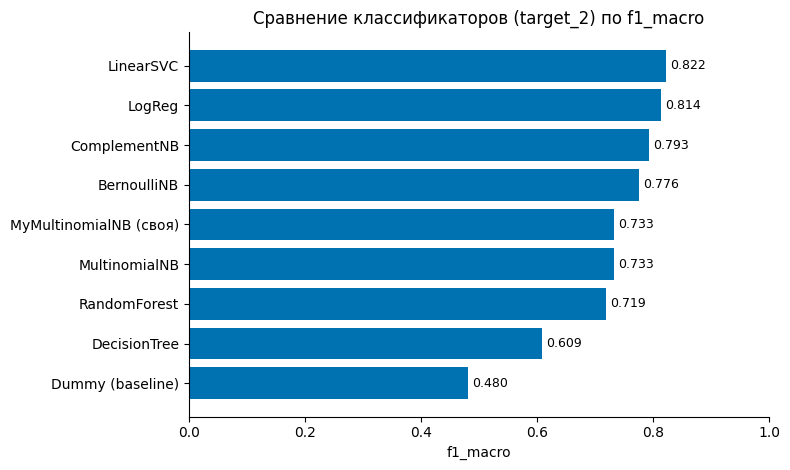

In [ ]:
# Бар-чарт по главной метрике
fig, ax = plt.subplots(figsize=(8, 4.8))
d = cmp.sort_values("f1_macro")
bars = ax.barh(d["model"], d["f1_macro"], color=OKABE[0])
ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax.set_xlim(0, 1); ax.set_xlabel("f1_macro")
ax.set_title("Сравнение классификаторов (target_2) по f1_macro")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

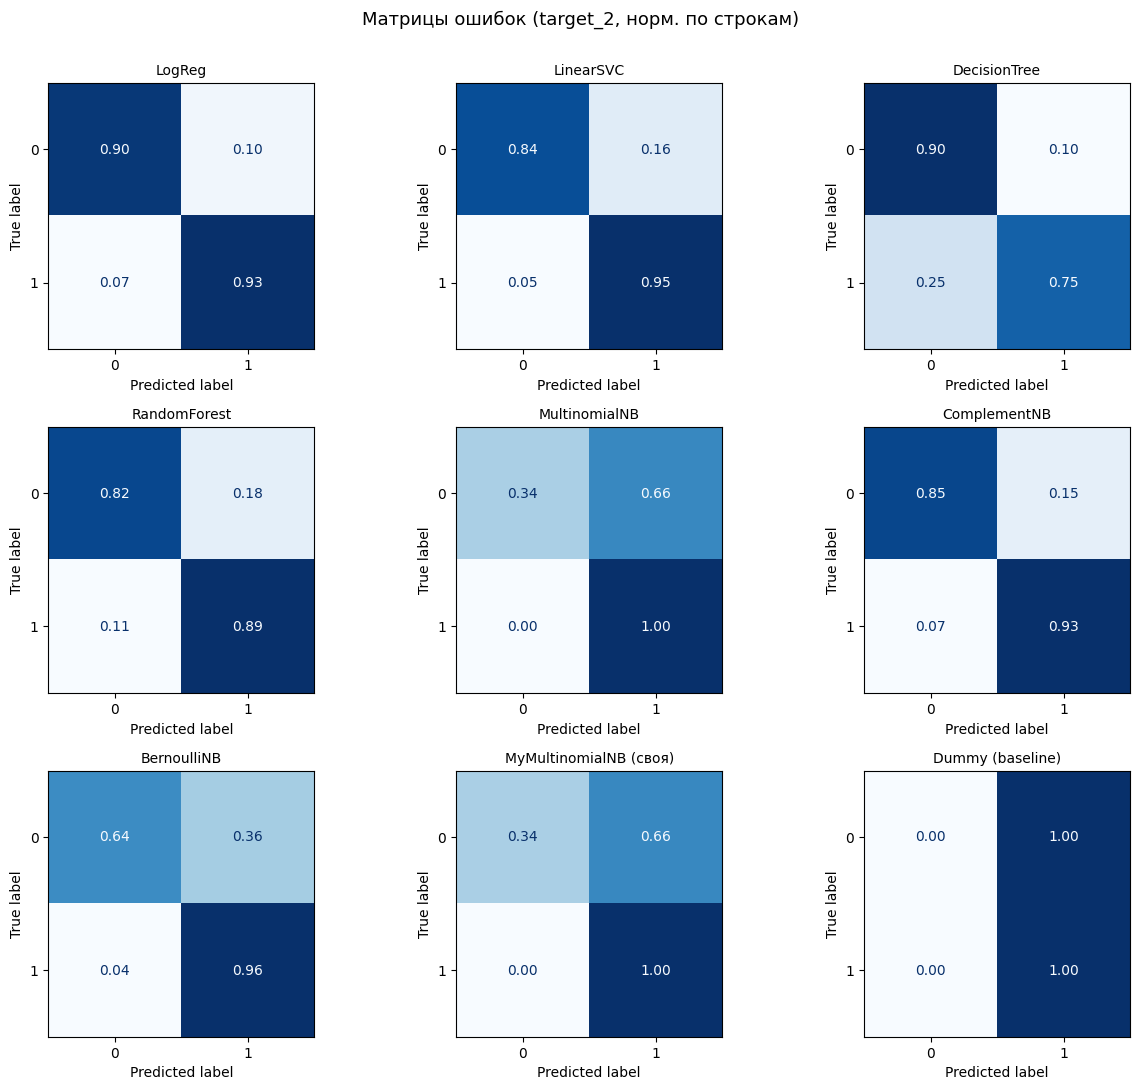

In [ ]:
# Матрицы ошибок по всем моделям (target_2, нормировка по строкам)
from sklearn.metrics import ConfusionMatrixDisplay

names = [n for n in models_zoo if n in CONF_MATRICES]
ncol = 3
nrow = int(np.ceil(len(names) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.6 * nrow))
axes = np.array(axes).ravel()
for ax, name in zip(axes, names):
    cm = CONF_MATRICES[name]
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    ConfusionMatrixDisplay(cm_norm, display_labels=[0, 1]).plot(
        cmap="Blues", colorbar=False, ax=ax, values_format=".2f")
    ax.set_title(name, fontsize=10)
for ax in axes[len(names):]:
    ax.axis("off")
fig.suptitle("Матрицы ошибок (target_2, норм. по строкам)", y=1.005, fontsize=13)
plt.tight_layout()
plt.show()

### ROC- и PR-кривые: подробный разбор (и почему ROC-AUC не делаем главной метрикой)

Все метрики по меткам (accuracy, f1 и т.д.) считаются по **готовым ответам 0/1**, которые модель выдаёт при пороге 0.5. Но на самом деле классификатор выдаёт не метку, а **оценку уверенности** `score` (у логрега и наивного Байеса — вероятность `predict_proba`; у `LinearSVC` — `decision_function`). ROC- и PR-кривые оценивают качество **самого ранжирования** по этой оценке, перебирая **все пороги сразу**, поэтому не зависят от конкретного выбора 0.5.

**ROC-кривая.** По осям:
- ось Y — **TPR (recall)**, доля верно пойманных положительных: $TPR=\dfrac{TP}{TP+FN}$;
- ось X — **FPR**, доля ложных тревог среди отрицательных: $FPR=\dfrac{FP}{FP+TN}$.

Каждая точка — пара (FPR, TPR) при некотором пороге. Сдвигая порог от «всё считаем положительным» к «всё отрицательным», проходим кривую из угла (1, 1) в (0, 0). Идеальная модель жмётся в **левый верхний угол** (поймали всех без ложных тревог), а **диагональ** — случайное угадывание.

**ROC-AUC = площадь под этой кривой.** Удобная для защиты интерпретация: **ROC-AUC — это вероятность, что случайно взятому положительному объекту модель поставит оценку выше, чем случайно взятому отрицательному.** 0.5 — монетка, 1.0 — идеальное ранжирование. Метрика **не зависит ни от порога, ни от пропорции классов**.

У нас (положительный класс = [4-5]): ROC-AUC ≈ **0.97** у `LogReg`, ≈ 0.96 у `LinearSVC` / `ComplementNB` / `MultinomialNB`, ≈ 0.95 у `BernoulliNB`, 0.93 у леса и даже у слабого дерева — **0.88**. По ранжированию «[4-5] против [0-3]» различают уверенно все модели.

**Почему здесь ROC-AUC «льстит» — и зачем нужна PR-кривая.** В знаменателе FPR стоит **TN** — огромный мажоритарный класс [4-5] (**96 568** объектов). Поэтому даже тысячи ложных тревог почти не двигают FPR, и ROC-AUC выходит высоким у всех: минор. класс здесь всего ≈ **7.5 %**, ROC-AUC ≥ 0.88 у каждой модели, хотя `f1_macro` разбегается от 0.61 до 0.82. Нас же интересует **миноритарный «плохой» класс [0-3]** (**7 853**). Его качество честнее показывает **PR-кривая** — precision против recall, где положительным считается именно [0-3]:
- ось Y — **precision** $=\dfrac{TP}{TP+FP}$ (из названных «плохими» — сколько реально плохих);
- ось X — **recall** $=\dfrac{TP}{TP+FN}$ (из всех плохих — сколько поймали).

**PR-AUC** (в таблице — `ap_bad`, average precision по классу [0-3]) не завязана на гигантский TN и потому строже. Её **базовый уровень = доля положительного класса**: для [0-3] это ≈ **0.075** (пунктир на правом графике), для [4-5] — ≈ 0.925. Сравните на `LogReg`: ROC-AUC 0.97 над «монеткой» 0.5 выглядит как у всех, а `ap_bad` = **0.81** над базой 0.075 — реальный запас над случайностью виден именно на PR, и именно он разводит сильные и слабые модели (у дерева `ap_bad` всего 0.45). Чем сильнее перекос, тем оптимистичнее ROC-AUC — а перекос у нас теперь сильный.

Поэтому в таблице мы держим **все три** ранжирующие метрики (`roc_auc`, `ap_good` по [4-5], `ap_bad` по [0-3]), но **главной** выбрали `f1_macro` (а `balanced_accuracy`, `ap_bad` и `MCC` — для контроля): они, в отличие от ROC-AUC, не «усыпляются» мажоритарным классом.

**Техническая деталь.** `LinearSVC` не выдаёт вероятностей — его ROC/PR строятся по `decision_function` (знаковому расстоянию до разделяющей гиперплоскости). На ранжирующие метрики (ROC-AUC, AP) это не влияет, а вероятностные (`log_loss`, `brier`) для него не определены — в таблице у него стоит `NaN`.

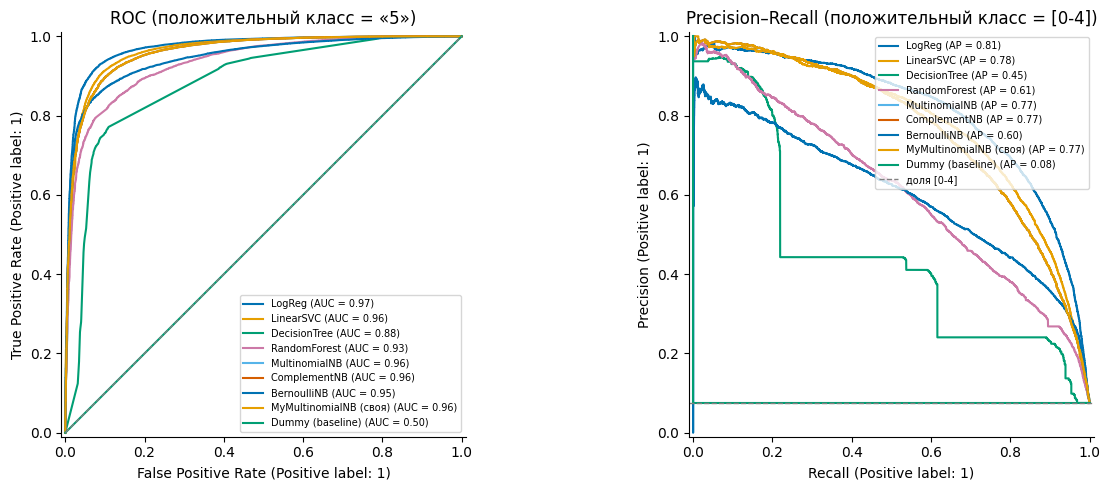

In [ ]:
# ROC и PR кривые по всем моделям (базовый зоопарк, target_2)
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

names = [n for n in models_zoo if SCORES.get(n) is not None]
palette = [OKABE[k % len(OKABE)] for k in range(len(names))]
fig, (axr, axp) = plt.subplots(1, 2, figsize=(13, 5))
axr.set_prop_cycle(color=palette)
axp.set_prop_cycle(color=palette)
for name in names:
    yt = PREDS[name][0]
    sc = SCORES[name]
    RocCurveDisplay.from_predictions(yt, sc, name=name, ax=axr)
    # PR для положительного = "плохой" класс [0-3]: ранжируем по -score
    PrecisionRecallDisplay.from_predictions(1 - yt, -sc, name=name, ax=axp)
axr.plot([0, 1], [0, 1], "--", color="gray", lw=1)
axr.set_title("ROC (положительный класс = [4-5])")
yt0 = PREDS[names[0]][0]
axp.axhline((yt0 == 0).mean(), ls="--", color="gray", lw=1, label="доля [0-3]")
axp.set_title("Precision–Recall (положительный класс = [0-3])")
axr.legend(fontsize=7, loc="lower right")
axp.legend(fontsize=7, loc="upper right")
for a in (axr, axp):
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 13.1 Снижение размерности (TruncatedSVD)

ДЗ допускает предварительное уменьшение размерности. Проверим, помогает ли оно, на примере `TruncatedSVD` + логистическая регрессия, и сравним с полным разреженным baseline.

Почему **`TruncatedSVD`**, а не `PCA`/`KernelPCA`: SVD (LSA) работает **прямо на разреженной матрице** без центрирования, тогда как PCA центрирует данные и делает матрицу плотной (для нашей матрицы ≈626 тыс. × десятки тысяч это десятки–сотни ГБ плотных чисел — непрактично). Это и методически корректный для текста выбор, и отличается от подхода с Kernel PCA.

In [ ]:
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import make_pipeline

svd_logreg = make_pipeline(
    TruncatedSVD(n_components=200, random_state=RANDOM_STATE),
    LogisticRegression(max_iter=1000, class_weight="balanced"),
)
row_svd = eval_model("LogReg + TruncatedSVD(200)", svd_logreg, split_2,
                     target_col="target_2", vec_kind="tfidf")

base_row = cmp.loc[cmp["model"] == "LogReg"].iloc[0].to_dict()
pd.DataFrame([base_row, row_svd])[
    ["model", "f1_macro", "balanced_acc", "roc_auc", "fit_s"]
].round(4)

,model,f1_macro,balanced_acc,roc_auc,fit_s
0,LogReg,0.8143,0.9192,0.9712,1.21
1,LogReg + TruncatedSVD(200),0.6857,0.8681,0.9365,22.12


## 13.2 Подбор гиперпараметров для всех моделей

По аналогии с тюнингом `C` (логрег) и `alpha` (наивный Байес) подбираем главный гиперпараметр **каждой** модели зоопарка через `GridSearchCV`:

- перебор внутри **тех же групповых CV-фолдов** `split_2["cv_folds"]` (без утечки по товарам), метрика отбора — `f1_macro`;
- векторизатор внутри `Pipeline` (fit на train каждого фолда), `memory=` кэширует TF-IDF, чтобы он не пересчитывался для каждого кандидата;
- лучшая модель переобучается на всём `trainval` (`refit=True`) и оценивается на нетронутом `test`.

Сетки намеренно небольшие. **`RandomForest` — самый тяжёлый**: если долго, уменьши сетку/`n_estimators` или временно закомментируй его строку в `tune_space`.

In [ ]:
import time
import tempfile
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV


def _test_row(name, fitted, split, target_col="target_2", text_col="preprocessed"):
    """Метрики уже обученной модели/пайплайна на общем test через _full_row."""
    text = df[text_col].to_numpy(); y = df[target_col].to_numpy()
    tr, te = split["trainval_idx"], split["test_idx"]
    yte = y[te]; Xte = text[te]
    t0 = time.perf_counter(); pred = fitted.predict(Xte); predict_s = time.perf_counter() - t0
    proba = fitted.predict_proba(Xte) if hasattr(fitted, "predict_proba") else None
    dec = fitted.decision_function(Xte) if (proba is None and hasattr(fitted, "decision_function")) else None
    return _full_row(name, yte, pred, len(tr), np.nan, predict_s,
                     classes=fitted.classes_, proba=proba, dec=dec)


def tune_model(name, estimator, param_grid, split, vec_kind="tfidf", cv=None, scoring="f1_macro"):
    """GridSearchCV по главному гиперпараметру внутри CV-фолдов; оценка лучшей на test."""
    text = df["preprocessed"].to_numpy(); y = df["target_2"].to_numpy()
    tr = split["trainval_idx"]
    cv = split["cv_folds"] if cv is None else cv
    pipe = Pipeline([("vec", _make_vec(vec_kind)), ("clf", estimator)], memory=tempfile.mkdtemp())
    grid = {f"clf__{k}": v for k, v in param_grid.items()}
    gs = GridSearchCV(pipe, grid, scoring=scoring, refit=True, cv=cv, n_jobs=-1, verbose=0)
    t0 = time.perf_counter(); gs.fit(text[tr], y[tr]); fit_s = time.perf_counter() - t0
    row = _test_row(name + " (tuned)", gs.best_estimator_, split)
    row["fit_s"] = round(fit_s, 2)            # полное время GridSearch+refit
    row["cv_f1_macro"] = round(gs.best_score_, 4)
    return gs, row, gs.best_params_

In [ ]:
# сетки: главный гиперпараметр каждой модели
tune_space = {
    "LogReg":        (LogisticRegression(max_iter=1000, class_weight="balanced"),
                      {"C": [0.01, 0.1, 1, 10, 100]}),
    "LinearSVC":     (LinearSVC(class_weight="balanced", dual=False),
                      {"C": [0.01, 0.1, 1]}),
    # min_samples_leaf как ДОЛЯ выборки -> авто-масштаб под размер данных
    # (на ~522k trainval: 0.0005~260, 0.002~1000, 0.01~5200 объектов на лист)
    "DecisionTree":  (DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
                      {"max_depth": [20, 40], "min_samples_leaf": [0.0005, 0.002, 0.01]}),
    "RandomForest":  (RandomForestClassifier(n_estimators=100, max_features="sqrt",
                                             class_weight="balanced_subsample", n_jobs=1,
                                             random_state=RANDOM_STATE),
                      {"max_depth": [20, 40, None], "min_samples_leaf": [0.0005, 0.005]}),
    "MultinomialNB": (MultinomialNB(), {"alpha": [0.01, 0.05, 0.1, 0.5, 1.0, 2.0]}),
    "ComplementNB":  (ComplementNB(), {"alpha": [0.01, 0.05, 0.1, 0.5, 1.0, 2.0]}),
    "BernoulliNB":   (BernoulliNB(), {"alpha": [0.1, 0.5, 1.0, 2.0]}),
    "MyMultinomialNB (своя)": (MyMultinomialNB(), {"alpha": [0.01, 0.05, 0.1, 0.5, 1.0, 2.0]}),
}

tuned_rows, best_params = [], {}
for name, (est, grid) in tune_space.items():
    print("Тюнинг:", name, grid)
    gs, row, bp = tune_model(name, est, grid, split_2)
    best_params[name] = bp
    tuned_rows.append(row)

tuned = pd.DataFrame(tuned_rows).sort_values("f1_macro", ascending=False).reset_index(drop=True)
display(pd.Series(best_params, name="best_params").to_frame())
tuned.round(4)

Тюнинг: LogReg {'C': [0.01, 0.1, 1, 10, 100]}
Тюнинг: LinearSVC {'C': [0.01, 0.1, 1]}
Тюнинг: DecisionTree {'max_depth': [20, 40], 'min_samples_leaf': [0.0005, 0.002, 0.01]}
Тюнинг: RandomForest {'max_depth': [20, 40, None], 'min_samples_leaf': [0.0005, 0.005]}
Тюнинг: MultinomialNB {'alpha': [0.01, 0.05, 0.1, 0.5, 1.0, 2.0]}
Тюнинг: ComplementNB {'alpha': [0.01, 0.05, 0.1, 0.5, 1.0, 2.0]}
Тюнинг: BernoulliNB {'alpha': [0.1, 0.5, 1.0, 2.0]}
Тюнинг: MyMultinomialNB (своя) {'alpha': [0.01, 0.05, 0.1, 0.5, 1.0, 2.0]}


,best_params
LogReg,{'clf__C': 10}
LinearSVC,{'clf__C': 1}
DecisionTree,"{'clf__max_depth': 40, 'clf__min_samples_leaf': 0.0005}"
RandomForest,"{'clf__max_depth': 40, 'clf__min_samples_leaf': 0.0005}"
MultinomialNB,{'clf__alpha': 0.05}
ComplementNB,{'clf__alpha': 2.0}
BernoulliNB,{'clf__alpha': 0.1}
MyMultinomialNB (своя),{'clf__alpha': 0.05}


,model,n_train,accuracy,balanced_acc,mcc,cohen_kappa,precision_macro,recall_macro,f1_macro,precision_micro,recall_micro,f1_micro,precision_weighted,recall_weighted,f1_weighted,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1,tn,fp,fn,tp,specificity_1,roc_auc,ap_good,ap_bad,log_loss,brier,fit_s,predict_s,cv_f1_macro
0,LogReg (tuned),522050,0.9385,0.9035,0.6646,0.6460,0.7737,0.9035,0.8222,0.9385,0.9385,0.9385,0.9560,0.9385,0.9444,0.5591,0.8622,0.6783,7853,0.9883,0.9447,0.9660,96568,6771,1082,5340,91228,0.8622,0.9672,0.9967,0.8015,0.1664,0.0467,35.06,0.570,0.8223
1,LinearSVC (tuned),522050,0.9395,0.8953,0.6608,0.6451,0.7761,0.8953,0.8218,0.9395,0.9395,0.9395,0.9551,0.9395,0.9448,0.5655,0.8434,0.6771,7853,0.9867,0.9473,0.9666,96568,6623,1230,5088,91480,0.8434,0.9631,0.9963,0.7822,NaN,NaN,32.04,0.578,0.8180
2,MultinomialNB (tuned),522050,0.9572,0.7714,0.6523,0.6382,0.8919,0.7714,0.8186,0.9572,0.9572,0.9572,0.9536,0.9572,0.9533,0.8192,0.5528,0.6601,7853,0.9646,0.9901,0.9772,96568,4341,3512,958,95610,0.5528,0.9634,0.9964,0.7715,0.1121,0.0320,25.47,0.578,0.8139
3,MyMultinomialNB (своя) (tuned),522050,0.9572,0.7714,0.6523,0.6382,0.8919,0.7714,0.8186,0.9572,0.9572,0.9572,0.9536,0.9572,0.9533,0.8192,0.5528,0.6601,7853,0.9646,0.9901,0.9772,96568,4341,3512,958,95610,0.5528,0.9634,0.9964,0.7715,0.1121,0.0320,26.93,0.576,0.8139
4,ComplementNB (tuned),522050,0.9438,0.8500,0.6379,0.6340,0.7906,0.8500,0.8168,0.9438,0.9438,0.9438,0.9502,0.9438,0.9464,0.6028,0.7397,0.6643,7853,0.9784,0.9604,0.9693,96568,5809,2044,3827,92741,0.7397,0.9540,0.9953,0.7502,0.1811,0.0480,25.25,0.599,0.8181
5,BernoulliNB (tuned),522050,0.9437,0.8349,0.6253,0.6232,0.7918,0.8349,0.8115,0.9437,0.9437,0.9437,0.9482,0.9437,0.9456,0.6078,0.7070,0.6537,7853,0.9759,0.9629,0.9693,96568,5552,2301,3582,92986,0.7070,0.9547,0.9954,0.6967,0.2699,0.0472,21.86,0.587,0.8108
6,RandomForest (tuned),522050,0.8666,0.8546,0.4821,0.4251,0.6638,0.8546,0.7049,0.8666,0.8666,0.8666,0.9369,0.8666,0.8905,0.3424,0.8406,0.4866,7853,0.9853,0.8687,0.9233,96568,6601,1252,12679,83889,0.8406,0.9311,0.9931,0.5998,0.6052,0.2065,102.05,1.093,0.7047
7,DecisionTree (tuned),522050,0.7944,0.8340,0.4002,0.3113,0.6199,0.8340,0.6341,0.7944,0.7944,0.7944,0.9325,0.7944,0.8399,0.2520,0.8806,0.3919,7853,0.9878,0.7874,0.8763,96568,6915,938,20526,76042,0.8806,0.9012,0.9880,0.4869,0.4181,0.1313,88.36,0.582,0.6379


In [ ]:
# Сравнение до/после тюнинга по f1_macro
base = cmp.set_index("model")["f1_macro"]
tun  = tuned.assign(base_name=tuned["model"].str.replace(" (tuned)", "", regex=False)) \
            .set_index("base_name")["f1_macro"]
delta = pd.DataFrame({"f1_macro_базовый": base, "f1_macro_тюнинг": tun})
delta["Δ"] = (delta["f1_macro_тюнинг"] - delta["f1_macro_базовый"]).round(4)
delta.dropna().sort_values("f1_macro_тюнинг", ascending=False).round(4)

,f1_macro_базовый,f1_macro_тюнинг,Δ
LogReg,0.8143,0.8222,0.0079
LinearSVC,0.8218,0.8218,0.0000
MultinomialNB,0.7333,0.8186,0.0854
MyMultinomialNB (своя),0.7333,0.8186,0.0854
ComplementNB,0.7926,0.8168,0.0242
BernoulliNB,0.7761,0.8115,0.0354
RandomForest,0.7194,0.7049,-0.0144
DecisionTree,0.6094,0.6341,0.0247


## 13.3 `classification_report` по каждой модели

Детальный отчёт по классам (precision / recall / f1 / support) для всех обученных моделей — базовых и тюнингованных. Предсказания берутся из `PREDS` (заполняется в `eval_model` и `_test_row`), без повторного обучения.

In [ ]:
from sklearn.metrics import classification_report

TARGET_NAMES = {0: "[0-3] (0)", 1: "[4-5] (1)"}
for name, (yt, pr) in PREDS.items():
    labels = sorted(np.unique(yt))
    print("=" * 72)
    print(name)
    print("=" * 72)
    print(classification_report(yt, pr, labels=labels,
          target_names=[TARGET_NAMES.get(l, str(l)) for l in labels],
          digits=3, zero_division=0))

LogReg
              precision    recall  f1-score   support

   [0-4] (0)      0.528     0.904     0.666      7853
     [5] (1)      0.992     0.934     0.962     96568

    accuracy                          0.932    104421
   macro avg      0.760     0.919     0.814    104421
weighted avg      0.957     0.932     0.940    104421

LinearSVC
              precision    recall  f1-score   support

   [0-4] (0)      0.566     0.843     0.677      7853
     [5] (1)      0.987     0.947     0.967     96568

    accuracy                          0.939    104421
   macro avg      0.776     0.895     0.822    104421
weighted avg      0.955     0.939     0.945    104421

DecisionTree
              precision    recall  f1-score   support

   [0-4] (0)      0.228     0.903     0.364      7853
     [5] (1)      0.990     0.752     0.854     96568

    accuracy                          0.763    104421
   macro avg      0.609     0.827     0.609    104421
weighted avg      0.932     0.763     0.818 

## 13.4 Строгая сверка собственной реализации со sklearn

Помимо совпадения метрик в таблице, сравним `MyMultinomialNB` и `sklearn.MultinomialNB` напрямую на одном TF-IDF: долю расхождений предсказаний на всём test, максимум |Δ вероятностей| и максимум |Δ параметров| (лог-вероятности признаков `feature_log_prob_` и лог-априоры `class_log_prior_`). Это прямое подтверждение корректности реализации (ДЗ, п. 7).

In [ ]:
vec = _make_vec("tfidf")
tr, te = split_2["trainval_idx"], split_2["test_idx"]
txt = df["preprocessed"].to_numpy(); y2 = df["target_2"].to_numpy()
Xtr = vec.fit_transform(txt[tr]); Xte = vec.transform(txt[te])
ytr, yte = y2[tr], y2[te]

skl = MultinomialNB(alpha=1.0).fit(Xtr, ytr)
my  = MyMultinomialNB(alpha=1.0).fit(Xtr, ytr)

pred_skl, pred_my = skl.predict(Xte), my.predict(Xte)
disagree   = float((pred_skl != pred_my).mean())
max_dproba = float(np.abs(skl.predict_proba(Xte) - my.predict_proba(Xte)).max())
max_dflp   = float(np.abs(skl.feature_log_prob_ - my.feature_log_prob_).max())
max_dclp   = float(np.abs(skl.class_log_prior_ - my.class_log_prior_).max())

print(f"Доля расхождений предсказаний на test : {disagree:.3e}  ({disagree*100:.4f} %)")
print(f"max |Δ predict_proba|                 : {max_dproba:.3e}")
print(f"max |Δ feature_log_prob_|             : {max_dflp:.3e}")
print(f"max |Δ class_log_prior_|              : {max_dclp:.3e}")
print()
if disagree <= 1e-6 and max_dproba < 1e-6:
    print("=> Реализации совпадают в пределах численной точности — своя MultinomialNB корректна.")
else:
    print("=> Есть расхождения: стоит проверить сглаживание / формат входа / типы данных.")

Доля расхождений предсказаний на test : 0.000e+00  (0.0000 %)
max |Δ predict_proba|                 : 2.665e-14
max |Δ feature_log_prob_|             : 1.776e-15
max |Δ class_log_prior_|              : 8.882e-16

=> Реализации совпадают в пределах численной точности — своя MultinomialNB корректна.


# 14. Выводы

**Главная метрика — `f1_macro`.** Таргет `target_2` сильно несбалансирован (класс [4-5] — ≈ **92.5 %**), поэтому `accuracy` завышается мажоритарным классом и для нашей цели неинформативна. Сейчас это особенно наглядно: `MultinomialNB` даёт **самую высокую accuracy (0.948)**, но это лишь на ~2 п.п. выше baseline `Dummy` (0.925), а ловит он только **34 %** «плохих» отзывов (`recall` класса [0-3] = 0.34), и его `f1_macro` = 0.733 — один из худших. Ориентируясь на accuracy, мы выбрали бы почти бесполезную для задачи модель. Поэтому главная метрика — `f1_macro` (усредняет F1 по классам с равным весом); подтверждающие — `balanced_accuracy`, `PR-AUC` (`ap_bad` по миноритарному классу) и `MCC`. `ROC-AUC` держим для полноты, но главной не делаем — подробно почему разобрано в секции с ROC/PR-кривыми выше (он характеризует ранжирование, а сам по себе дисбаланс не повышает его значение).

**Сравнение моделей** (базовый зоопарк, сортировка по `f1_macro`; точные числа — в таблице):

- **линейные модели лидируют**: `LinearSVC` (0.822) и `LogReg` (0.814) — высокоразмерные разреженные тексты хорошо разделяются линейно (по `balanced_accuracy` впереди `LogReg` — 0.919; на вершине они фактически вровень);
- `ComplementNB` (0.793) заметно опережает `MultinomialNB` (0.733) — на сильном дисбалансе его устойчивость видна особенно ярко (он для этого и создан);
- `BernoulliNB` (0.776) конкурентоспособен на коротких текстах (учитывает сам факт наличия слова);
- `RandomForest` (0.719) и особенно `DecisionTree` (0.609) на разреженных признаках слабее линейных и дороже по времени (`fit_s`: дерево 16.9 c против 1.2 c у логрега);
- `Dummy` (0.481) — нижняя граница: при accuracy 0.925 его `f1_macro` всего 0.481 — ещё раз о бессмысленности accuracy на таком перекосе.

**Снижение размерности (13.1):** `TruncatedSVD(200)` + логрег даёт `f1_macro` = 0.686 против **0.814** у полного разреженного baseline — заметно **хуже**. Значит в основном пайплайне снижать размерность не нужно; это осознанный, подтверждённый числами выбор.

**Эффект тюнинга (13.2):** после подбора лучшей становится **`LogReg (tuned)` с `f1_macro` = 0.822**, вровень с `LinearSVC` (0.822). Самый большой прирост дал подбор `alpha` у наивного Байеса — **`MultinomialNB`/своя +0.085** (0.733 → 0.819, оптимум `alpha = 0.05`): при сильном дисбалансе дефолтное сглаживание `alpha = 1` занижало recall миноритарного класса, и его снижение резко помогло. Далее `BernoulliNB` +0.035, `DecisionTree` +0.025, `ComplementNB` +0.024, `LogReg` +0.008 (`C = 10`); у `LinearSVC` прирост нулевой (`C = 1` и был оптимумом). Снова показателен **`RandomForest`: после тюнинга стал ХУЖЕ (−0.014)** — отбор по CV не гарантирует улучшения на `test`. Конкретные параметры — в `best_params`, приросты — в Δ-таблице.

**Своя реализация vs sklearn:** `MyMultinomialNB` и `sklearn.MultinomialNB` дают **бит-в-бит одинаковые метрики** (`f1_macro` = 0.7333 у обеих, |Δ| = 0.0000). Прямая сверка (13.4): доля расхождений предсказаний на `test` = **0.0000 %**, `max|Δ predict_proba|` ≈ 3·10⁻¹⁴, `max|Δ параметров|` ≈ 10⁻¹⁵ — уровень машинной точности. Реализована в точности та же математика (лог-априоры + лог-правдоподобия со сглаживанием Лапласа) — корректность подтверждена строго.

**Чем наш подход отличается от подхода коллеги** (и почему обоснован):

- полный разреженный TF-IDF **без снижения размерности** вместо Kernel PCA — для линейных моделей и NB уместнее, а снижение проверено и отвергнуто числами (13.1);
- **групповой сплит по `product_id` + кросс-валидация** — защита от утечки (отзывы одного товара не попадают одновременно в train и test);
- своя реализация — **MultinomialNB** (каноничен для текста, работает на разреженных счётчиках), а не GaussianNB;
- `SVM` берём как `LinearSVC` по той же причине масштабируемости, без ядрового преобразования.

In [ ]:
# Авто-сводка для выводов (числа берутся из таблицы cmp)
best = cmp.iloc[0]
print(f"Лучшая модель по f1_macro: {best['model']}  (f1_macro = {best['f1_macro']:.4f})")

mnb = cmp.loc[cmp['model'] == 'MultinomialNB', 'f1_macro'].values[0]
my  = cmp.loc[cmp['model'] == 'MyMultinomialNB (своя)', 'f1_macro'].values[0]
print(f"MultinomialNB: sklearn f1_macro = {mnb:.4f}  |  своя = {my:.4f}  |  |d| = {abs(mnb - my):.4f}")

dummy = cmp.loc[cmp['model'] == 'Dummy (baseline)', 'f1_macro'].values[0]
print(f"Baseline (Dummy) f1_macro = {dummy:.4f}  ->  лучшая модель выше baseline на {best['f1_macro'] - dummy:.4f}")

# после тюнинга (если секция 13.2 выполнена)
try:
    bt = tuned.iloc[0]
    print(f"Лучшая модель ПОСЛЕ тюнинга: {bt['model']}  (f1_macro = {bt['f1_macro']:.4f})")
    dd = delta.dropna()
    g = dd["Δ"].idxmax()
    print(f"Наибольший прирост от тюнинга: {g}  (Δf1_macro = +{dd.loc[g, 'Δ']:.4f})")
except NameError:
    print("(ячейки тюнинга 13.2 ещё не выполнены)")


Лучшая модель по f1_macro: LinearSVC  (f1_macro = 0.8218)
MultinomialNB: sklearn f1_macro = 0.7333  |  своя = 0.7333  |  |d| = 0.0000
Baseline (Dummy) f1_macro = 0.4805  ->  лучшая модель выше baseline на 0.3414
Лучшая модель ПОСЛЕ тюнинга: LogReg (tuned)  (f1_macro = 0.8222)
Наибольший прирост от тюнинга: MultinomialNB  (Δf1_macro = +0.0854)


# 15. Сравнение подходов


### 15.1 Чем различаются пайплайны

| Аспект | 1 подход | 2 подход |
|---|---|---|
| Представление | полный разреженный **TF-IDF** (`min_df=5`, 1–2-граммы), **без снижения размерности** | TF-IDF (`max_features=50k`, `sublinear_tf`) → **Kernel PCA (RBF) до 64 плотных признаков** (обучен на 1024 опорных точках) + `StandardScaler` |
| Своя реализация | **MultinomialNB**  | **GaussianNB**  |
| Учёт дисбаланса | `class_weight="balanced"` | `class_weight="balanced"` + `sample_weight` на NB |


### 15.2 Результаты: кто выигрывает в каждом пайплайне

Лучшие модели по `f1_macro` на **test**:

| | 1 подход | 2 подход |
|---|---|---|
| 🥇 лучшая | **LinearSVC 0.822** (после тюнинга LogReg 0.822) | **Случайный лес 0.706** |
| линейные (LogReg / SVM) | **0.814 / 0.822** — верх таблицы | **0.586 / 0.578** — низ таблицы |
| деревья (RF / DT) | 0.719 / 0.609 — ниже линейных | **0.706 / 0.626** — верх таблицы |
| наивный Байес (лучший) | ComplementNB 0.793 | BernoulliNB 0.549 |
| своя реализация | MultinomialNB 0.733 | GaussianNB **0.332 — ниже baseline** |
| baseline (Dummy) | 0.481 | 0.480 — **совпадает** |

На разреженном TF-IDF линейные модели лидируют (0.81–0.82), деревья ниже; после Kernel PCA до 64 признаков — наоборот, лес наверху (0.71), а линейные модели отрабатывают хуже (LogReg ≈0.81 → ≈0.59). Любопытно, что **лес в обоих пайплайнах ≈0.71** — то есть Kernel PCA бьёт именно по линейным моделям, а не по деревьям. Итог: лучший результат 1 подхода (**0.82**) на той же задаче заметно выше лучшего на 2 подходе (**0.71**). Почему так:
- текст в TF-IDF линейно разделим в высокой размерности — типовая ситуация для логрега/SVM;
- Kernel PCA сжимает всё в 64 плотных нелинейных признака: линейная граница там уже мало что ловит, зато деревья/лес хорошо режут нелинейное пространство.

На тех же данных и таргете: `TruncatedSVD(200)` + логрег дал 0.686 против 0.814 на полном TF-IDF (13.1). KPCA-64 — ещё более агрессивное сжатие, и падение линейных моделей там сильнее — тот же механизм.

### 15.3 Почему выбор представления меняет картину

- **Выбор вида NB.** После Kernel PCA признаки — плотные вещественные числа (с отрицательными), поэтому Multinomial/Complement NB (им нужны неотрицательные значения) **неприменимы** — остаётся GaussianNB. У Павла во 2-ом подходе он дал `F1_macro` 0.332, **ниже baseline** (гауссово предположение на KPCA-компонентах плохо описывает данные). В 1-ом подходе брались модели, подходящие тексту, Multinomial/Complement/Bernoulli — и все они уверенно выше baseline.
- **Ресурсы.** Наша лучшая модель (LogReg) обучается ≈ **1.2 c** на разреженной матрице. Лучшая у Павла Random Forest на 64 плотных признаках — ≈ **580 c** только на `fit`, плюс отдельная стоимость обучения и применения Kernel PCA. Более тяжёлый пайплайн дал при этом **меньший** `F1_macro`.

### 15.4 Своя реализация — у обоих подтверждена строго

Методологически здесь мы совпадаем: оба сверили свою реализацию со sklearn и получили совпадение до машинной точности.
- 1 подход: `MyMultinomialNB` vs `sklearn.MultinomialNB` — **0.0000 %** расхождений предсказаний, `max|Δ вероятностей|` ≈ 2·10⁻¹⁴;
- 2 подход: свой `GaussianNB` vs `sklearn.GaussianNB` — **0 %** расхождений, `max|Δ вероятностей|` ≈ 3·10⁻¹².